# 01 · Khám phá dữ liệu (EDA)

Bước 2-3 của quy trình end-to-end (Ch.2): lấy dữ liệu, xem cấu trúc, trực quan hóa và tìm tương quan. Notebook **không** sửa CSV gốc trong `data/raw/`. Xây dựng và so sánh mô hình nằm ở `02_model_training.ipynb`.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "app").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", None)
from app.train import load_dataset, prepare_dataset
data = load_dataset()
print(data.shape)
data.head()

(5000, 13)


,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


## 1. Cấu trúc, kiểu dữ liệu, giá trị thiếu, trùng lặp

In [2]:
display(data.dtypes.to_frame('dtype').T)
print('Giá trị thiếu:', int(data.isna().sum().sum()))
print('Dòng trùng lặp hoàn toàn:', int(data.duplicated().sum()))
print('Physical_Activity_Hours âm:', int((data['Physical_Activity_Hours'] < 0).sum()))
data.describe().T.round(2)

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
dtype,int64,str,str,str,str,str,float64,int64,float64,float64,float64,str,float64


Giá trị thiếu: 0
Dòng trùng lặp hoàn toàn: 2
Physical_Activity_Hours âm: 10


,count,mean,std,min,25%,50%,75%,max
Age,5000.0,20.82,1.74,18.0,19.0,21.0,22.0,24.0
Avg_Daily_Usage_Hours,5000.0,5.08,1.65,1.0,3.8,5.0,6.3,8.8
Daily_Unlocks,5000.0,171.45,42.86,62.0,140.0,171.0,204.0,273.0
Study_Hours,5000.0,3.01,1.64,0.3,1.5,2.8,4.2,8.3
Physical_Activity_Hours,5000.0,1.75,0.67,-0.4,1.3,1.7,2.2,4.1
Sleep_Hours_Per_Night,5000.0,6.63,1.22,3.6,5.6,6.6,7.5,9.9
Mental_Health_Score,5000.0,6.23,1.28,3.6,5.1,6.1,7.1,9.4


## 2. Phân tích đơn biến: biến mục tiêu và biến phân loại

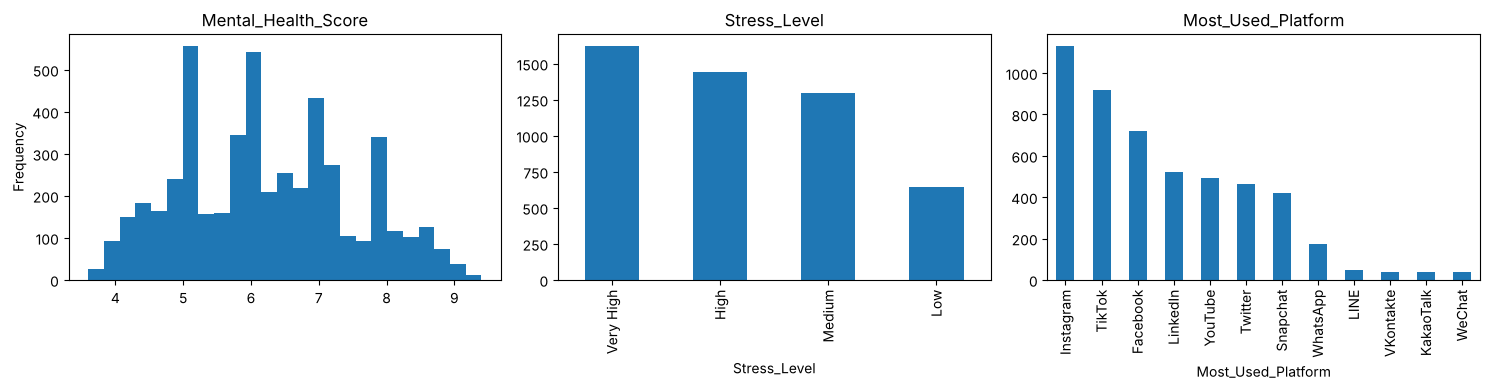

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
data['Mental_Health_Score'].plot.hist(bins=25, ax=axes[0], title='Mental_Health_Score')
data['Stress_Level'].value_counts().plot.bar(ax=axes[1], title='Stress_Level')
data['Most_Used_Platform'].value_counts().plot.bar(ax=axes[2], title='Most_Used_Platform')
plt.tight_layout(); plt.show()

### Độ phủ của `Country` (feature generalization, Chip Huyen ch.5)
Nhiều quốc gia chỉ có vài dòng: mô hình khó tổng quát cho các nhóm này (sampling bias, Ch.1).

In [4]:
counts = data['Country'].value_counts()
print('Số quốc gia:', counts.size)
print('Quốc gia có < 30 dòng:', int((counts < 30).sum()))
print('Vietnam:', int(counts.get('Vietnam', 0)), 'dòng')
counts.head(10)

Số quốc gia: 111
Quốc gia có < 30 dòng: 85
Vietnam: 5 dòng


Country
Other        1880
India         389
USA           355
Canada        230
Australia     198
UK            185
Germany       136
Mexico         94
Turkey         94
France         87
Name: count, dtype: int64

## 3. Phân tích hai biến: tương quan và quan hệ phi tuyến
Hệ số tương quan Pearson chỉ đo quan hệ **tuyến tính** (Ch.2 slide 23), nên ta xem thêm điểm trung bình theo nhóm.

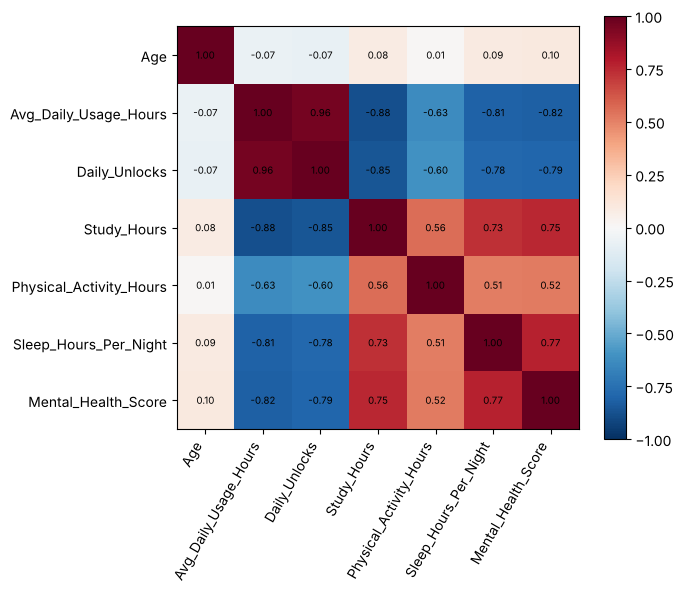

In [5]:
num = ['Age','Avg_Daily_Usage_Hours','Daily_Unlocks','Study_Hours','Physical_Activity_Hours','Sleep_Hours_Per_Night','Mental_Health_Score']
corr = data[num].corr()
fig, ax = plt.subplots(figsize=(7,6))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=60, ha='right'); ax.set_yticks(range(len(num))); ax.set_yticklabels(num)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center', fontsize=7)
fig.colorbar(im); plt.tight_layout(); plt.show()

,mean,count
Avg_Daily_Usage_Hours,,
"(0, 2]",7.99,153
"(2, 3]",7.98,442
"(3, 4]",7.41,896
"(4, 5]",6.49,1010
"(5, 6]",5.75,1004
"(6, 7]",4.98,804
"(7, 9]",4.98,691


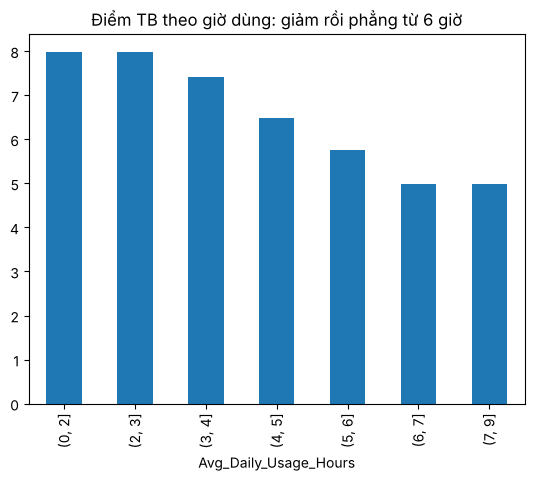

In [6]:
bins = pd.cut(data['Avg_Daily_Usage_Hours'], [0,2,3,4,5,6,7,9])
table = data.groupby(bins, observed=True)['Mental_Health_Score'].agg(['mean','count']).round(2)
display(table)
table['mean'].plot.bar(title='Điểm TB theo giờ dùng: giảm rồi phẳng từ 6 giờ'); plt.show()

In [7]:
print('Ngủ >= 7 giờ vs < 7 giờ:')
print(data.groupby(data['Sleep_Hours_Per_Night'] >= 7)['Mental_Health_Score'].mean().round(2))

Ngủ >= 7 giờ vs < 7 giờ:
Sleep_Hours_Per_Night
False    5.44
True     7.31
Name: Mental_Health_Score, dtype: float64


## 4. Phân tích đa biến: Stress_Level đi cùng giờ dùng
Điểm chênh rất lớn giữa các mức stress, nhưng giờ dùng cũng tăng theo stress, nên hai biến mang thông tin trùng nhau.

In [8]:
display(data.groupby('Stress_Level')[['Mental_Health_Score','Avg_Daily_Usage_Hours','Sleep_Hours_Per_Night']].mean().round(2).loc[['Low','Medium','High','Very High']])

,Mental_Health_Score,Avg_Daily_Usage_Hours,Sleep_Hours_Per_Night
Stress_Level,,,
Low,7.84,2.78,8.16
Medium,7.14,3.86,7.57
High,6.03,5.19,6.45
Very High,5.05,6.87,5.44


### Nền tảng hay quốc gia? (kiểm tra biến gây nhiễu)
Điểm TB theo nền tảng chênh lớn. Bảng chéo cho thấy nền tảng có gắn với quốc gia hay không.

In [9]:
display(data.groupby('Most_Used_Platform')['Mental_Health_Score'].agg(['mean','count']).round(2).sort_values('mean'))
for p in ['LINE','KakaoTalk','VKontakte','WeChat']:
    top = data.loc[data['Most_Used_Platform']==p, 'Country'].value_counts(normalize=True).head(3).round(2)
    print(p, dict(top))

,mean,count
Most_Used_Platform,,
WhatsApp,5.58,175
KakaoTalk,5.98,36
TikTok,5.99,918
Snapchat,6.12,420
Instagram,6.19,1130
YouTube,6.22,491
Twitter,6.35,462
Facebook,6.40,719
LinkedIn,6.48,523


LINE {'Japan': np.float64(1.0)}
KakaoTalk {'South Korea': np.float64(1.0)}
VKontakte {'Russia': np.float64(1.0)}
WeChat {'China': np.float64(1.0)}


## Kết luận EDA
1. Dữ liệu sạch: 0 giá trị thiếu, 2 dòng trùng, 10 giá trị vận động âm (chặn về 0 khi huấn luyện).
2. Giờ dùng mạng xã hội và giờ ngủ là hai yếu tố mạnh nhất; quan hệ với giờ dùng là **phi tuyến** (có ngưỡng) nên mô hình cây phù hợp hơn hồi quy tuyến tính.
3. `Stress_Level` gần như trùng thông tin với giờ dùng.
4. `Country` có độ phủ rất lệch (Vietnam 5 dòng), nên API phải cảnh báo khi dự đoán cho nhóm hiếm.
5. Tất cả là **tương quan**, không phải nhân quả.